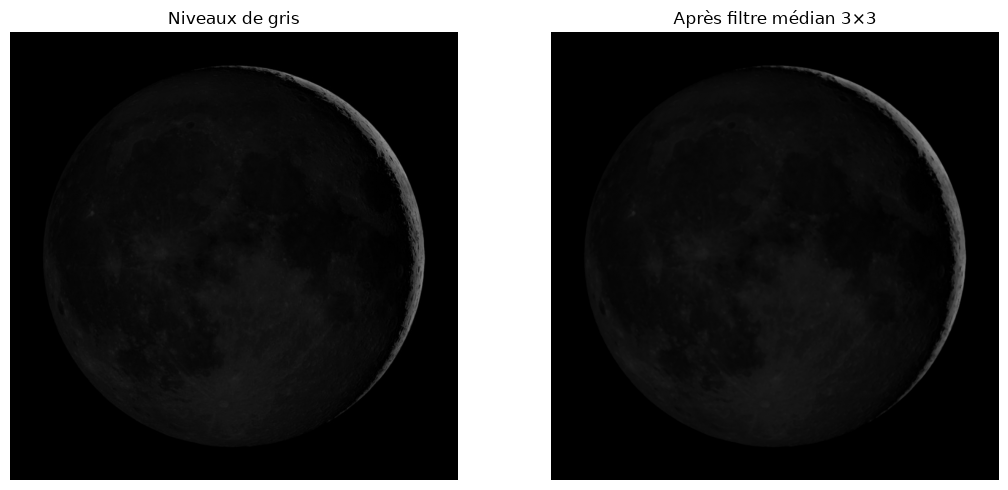

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from skimage import color

CHEMIN = "images/moon.7545.jpg"

# Chargement
I = plt.imread(CHEMIN)
if I.dtype == np.uint8:                  # jpg : entiers 0..255 -> flottants 0..1
    I = I.astype(float) / 255
if I.ndim == 3:                          # couleur -> niveaux de gris
    I = color.rgb2gray(I[:, :, :3])

k = max(1, max(I.shape) // 600)          # grosse photo : on garde 1 pixel sur k
I = I[::k, ::k]

# Filtre médian 3x3
J = signal.medfilt2d(I, kernel_size=3)

# Affichage
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(I, cmap='gray', vmin=0, vmax=1);  ax[0].set_title("Niveaux de gris")
ax[1].imshow(J, cmap='gray', vmin=0, vmax=1);  ax[1].set_title("Après filtre médian 3×3")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

Nombre d'objets détectés : 11


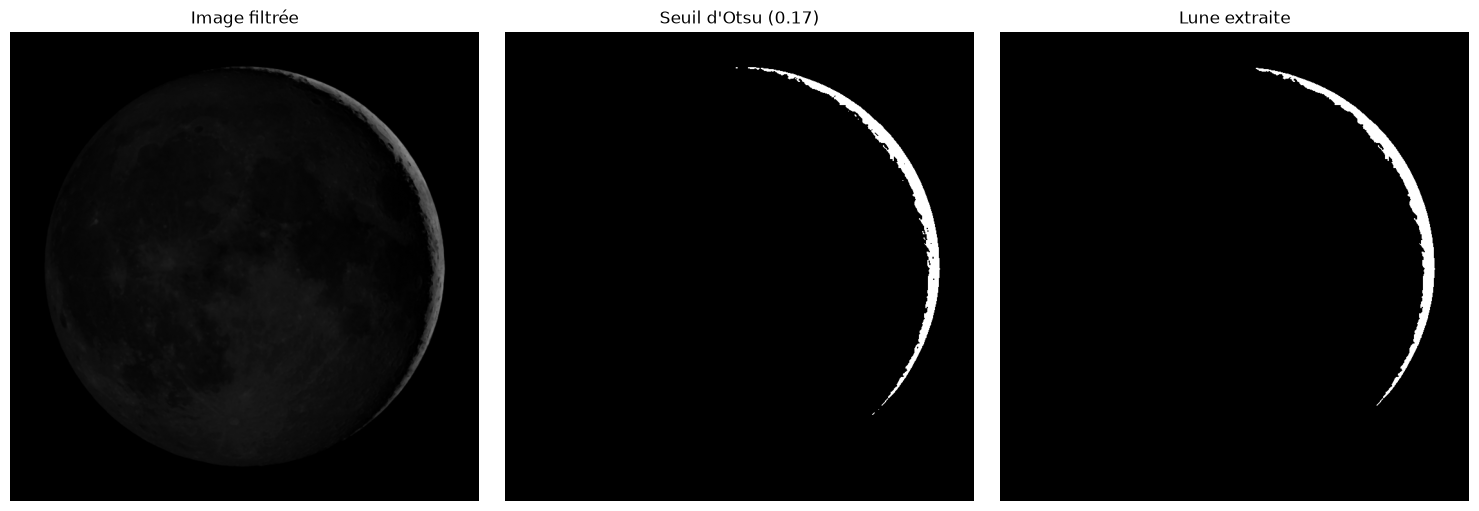

In [4]:
from scipy import ndimage
from skimage import filters, measure

# Seuil d'Otsu : sépare le ciel sombre de la lune
seuil = filters.threshold_otsu(J)
masque = J > seuil

# Étiquetage : chaque objet connexe reçoit un numéro
L, n = measure.label(masque, return_num=True)
print("Nombre d'objets détectés :", n)

# On garde uniquement l'objet le plus grand (la lune)
aires = [p.area for p in measure.regionprops(L)]
plus_grand = np.argmax(aires) + 1
masque = (L == plus_grand)

# Remplit les zones sombres à l'intérieur de la lune (surtout utile en pleine lune)
masque = ndimage.binary_fill_holes(masque)

# Affichage
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(J, cmap='gray', vmin=0, vmax=1);  ax[0].set_title("Image filtrée")
ax[1].imshow(J > seuil, cmap='gray');          ax[1].set_title(f"Seuil d'Otsu ({seuil:.2f})")
ax[2].imshow(masque, cmap='gray');             ax[2].set_title("Lune extraite")
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

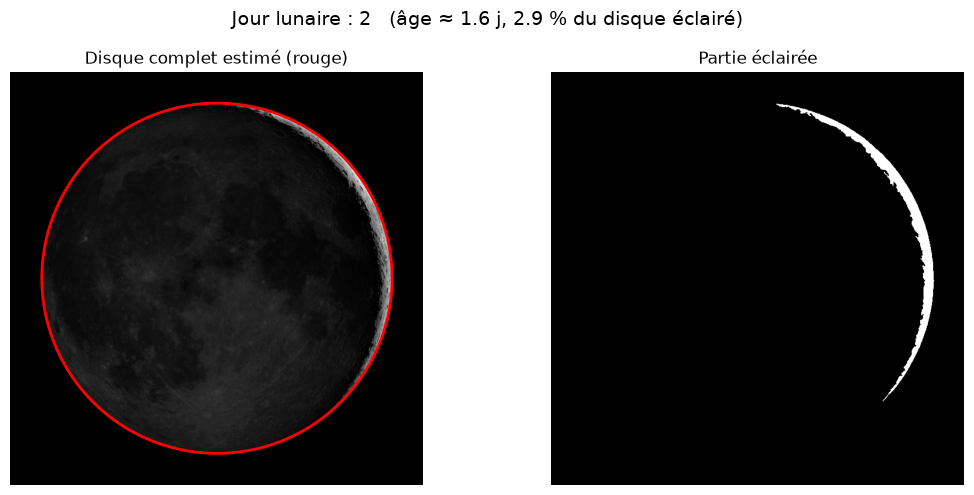

In [6]:
from scipy.spatial.distance import cdist
from skimage import morphology, segmentation

CROISSANTE = True       # False si la lune est décroissante
PERIODE = 29.53         # durée du mois lunaire en jours


def ajuster_cercle(x, y):
    # Moindres carrés (méthode de Kåsa) : x² + y² = 2·a·x + 2·b·y + c  -> équation linéaire en (a, b, c)
    A = np.column_stack([2 * x, 2 * y, np.ones_like(x)])
    second_membre = x**2 + y**2
    (a, b, c), *_ = np.linalg.lstsq(A, second_membre, rcond=None)
    return a, b, np.sqrt(c + a**2 + b**2)              # centre (a, b) et rayon


def estimer_disque(masque):
    # Enveloppe convexe de la zone éclairée (pour un croissant : le limbe + la corde entre les 2 pointes)
    enveloppe = morphology.convex_hull_image(masque)
    bord_env = segmentation.find_boundaries(enveloppe, mode='inner')

    # Estimation 1 : cercle dont le diamètre est la plus grande corde (= distance entre les 2 pointes)
    pts = np.argwhere(bord_env)[:, ::-1].astype(float)  # coordonnées (x, y)
    D = cdist(pts, pts)
    i, j = np.unravel_index(np.argmax(D), D.shape)
    centre, R = (pts[i] + pts[j]) / 2, D[i, j] / 2
    if masque.sum() / (np.pi * R**2) >= 0.5:            # gibbeuse ou pleine : l'estimation 1 suffit
        return centre[0], centre[1], R

    # Estimation 2 (croissant) : cercle ajusté sur le limbe = points du contour qui touchent l'enveloppe
    contour = segmentation.find_boundaries(masque, mode='inner')
    proche = ndimage.binary_dilation(bord_env, iterations=2)
    y, x = np.nonzero(contour & proche)
    x, y = x.astype(float), y.astype(float)
    cx, cy, R = ajuster_cercle(x, y)
    for _ in range(3):                                  # on écarte les points loin du cercle, puis on refait l'ajustement
        ecart = np.abs(np.hypot(x - cx, y - cy) - R)
        garde = ecart < max(2.0, 2 * np.median(ecart))
        if garde.sum() < 10:
            break
        cx, cy, R = ajuster_cercle(x[garde], y[garde])
    return cx, cy, R


cx, cy, R = estimer_disque(masque)

# Fraction éclairée -> âge lunaire
f = min(1.0, masque.sum() / (np.pi * R**2))
age = np.arccos(1 - 2 * f) * PERIODE / (2 * np.pi)
if not CROISSANTE:
    age = PERIODE - age
jour = int(age) + 1

# Affichage : image + disque complet estimé
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(I, cmap='gray')
ax[0].add_patch(plt.Circle((cx, cy), R, fill=False, color='r', lw=2))
ax[0].set_title("Disque complet estimé (rouge)")
ax[1].imshow(masque, cmap='gray');  ax[1].set_title("Partie éclairée")
for a in ax:
    a.axis('off')
fig.suptitle(f"Jour lunaire : {jour}   (âge ≈ {age:.1f} j, {100 * f:.1f} % du disque éclairé)", fontsize=14)
plt.tight_layout()
plt.show()